## Traffic Sign Classification with Deep Learning

Classification of 43 GTSRB traffic sign categories using an MLP, a LeNet-5-inspired CNN, regularization and augmentation experiments, and zero-shot CLIP.

### Interpretation of saved experiments

 The augmentation experiment uses the full official training split, including the validation subset, and the winning configuration is selected by test accuracy. These design choices limit the independence of validation and the final selected-model estimate. See README.md for details. Code and numeric outputs are retained so these issues remain inspectable.


### 1) Project Goal

The goal of this project is to develop and evaluate a deep learning–based traffic sign classification system using the GTSRB dataset (43 classes).

We first implement a simple neural network baseline (MLP) to establish a reference performance level. We then design and train a LeNet-5 inspired CNN to leverage convolutional feature extraction for improved accuracy. In addition, we analyze the impact of training improvements such as data augmentation, dropout, and batch normalization.

Finally, we compare our trained CNN with a foundation model (CLIP) in a zero-shot setting to assess how a pretrained vision-language model performs on this task.

Our expectation is that the CNN will significantly outperform the baseline neural network, and that training improvements will further enhance generalization performance.

### 2) Input and Ground Truth

- **Input:** RGB image of a traffic sign (resized to a fixed size).
- **Ground truth:** one of **43 class labels** (0–42) from GTSRB.

In [ ]:
## ✅ Imports and Setup

%matplotlib inline

import os
import sys
import time
import math
import random
import platform
from dataclasses import dataclass
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

# PyTorch / Torchvision for CNN pipeline
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split, Subset
import torchvision
from torchvision import transforms
import torchvision.transforms as T
from torchvision.datasets import GTSRB

# Scikit-learn for evaluation metrics
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

Python: 3.12.12
Platform: Linux-6.6.113+-x86_64-with-glibc2.35
Torch: 2.10.0+cpu
Torchvision: 0.25.0+cpu


In [ ]:
## ✅ Reproducibility

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Deterministic settings (may reduce speed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [ ]:
## ✅ Class Names / Label Names (GTSRB 43 classes)

GTSRB_LABELS = [
    "Speed limit (20km/h)",
    "Speed limit (30km/h)",
    "Speed limit (50km/h)",
    "Speed limit (60km/h)",
    "Speed limit (70km/h)",
    "Speed limit (80km/h)",
    "End of speed limit (80km/h)",
    "Speed limit (100km/h)",
    "Speed limit (120km/h)",
    "No passing",
    "No passing for vehicles over 3.5 metric tons",
    "Right-of-way at the next intersection",
    "Priority road",
    "Yield",
    "Stop",
    "No vehicles",
    "Vehicles over 3.5 metric tons prohibited",
    "No entry",
    "General caution",
    "Dangerous curve to the left",
    "Dangerous curve to the right",
    "Double curve",
    "Bumpy road",
    "Slippery road",
    "Road narrows on the right",
    "Road work",
    "Traffic signals",
    "Pedestrians",
    "Children crossing",
    "Bicycles crossing",
    "Beware of ice/snow",
    "Wild animals crossing",
    "End of all speed and passing limits",
    "Turn right ahead",
    "Turn left ahead",
    "Ahead only",
    "Go straight or right",
    "Go straight or left",
    "Keep right",
    "Keep left",
    "Roundabout mandatory",
    "End of no passing",
    "End of no passing by vehicles over 3.5 metric tons",
]

NUM_CLASSES = len(GTSRB_LABELS)
assert NUM_CLASSES == 43, "GTSRB should have exactly 43 classes"

print("Number of classes:", NUM_CLASSES)
print("Example label[1]:", GTSRB_LABELS[1])

Number of classes: 43
Example label[1]: Speed limit (30km/h)


### 3) Dataset Description (GTSRB)

We use the **German Traffic Sign Recognition Benchmark (GTSRB)**:
- Public dataset (Torchvision + Kaggle versions exist)
- More than 50,000 images in total
- 43 classes, with class counts ranging approximately 200 to 2000 images
- Images are provided as PNG files in many distributions

### 4) Data Processing

Images are resized to 32 x 32 RGB and normalized with ImageNet statistics. The official training split is divided randomly into training and validation subsets (15% validation, seed 42); the official test split is retained.

**Implementation limitation:** `train_loader_aug` below uses `train_full_aug`, which includes validation indices. The loader labeled as the non-augmented CNN training loader also uses augmented `train_ds`. The saved experiment labels therefore do not describe a clean augmentation ablation.


In [ ]:
## ✅ Load Full GTSRB (train + test) using Torchvision
DATA_DIR     = "./data"
IMG_SIZE     = 32
VAL_FRACTION = 0.15
SEED         = 42

# Base transform (validation/test): resize + tensor scaling [0,1]
base_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std =[0.229, 0.224, 0.225]
    )
])

# Technique #1 (required): Data augmentation - ONLY for training
train_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.RandomAffine(degrees=15, translate=(0.08, 0.08), scale=(0.9, 1.1)),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std =[0.229, 0.224, 0.225]
    )
])

# We split the official GTSRB training data into training and validation sets using a
# fixed seed, while keeping the test set completely separate for final evaluation.

# Load official splits
train_full_base = GTSRB(root=DATA_DIR, split="train", download=True, transform=base_transform)
train_full_aug  = GTSRB(root=DATA_DIR, split="train", download=True, transform=train_transform)
test_ds         = GTSRB(root=DATA_DIR, split="test",  download=True, transform=base_transform)

# Split train into train/val (fixed seed)
n_total = len(train_full_base)
n_val   = int(VAL_FRACTION * n_total)
n_train = n_total - n_val

generator = torch.Generator().manual_seed(SEED)
train_idx, val_idx = random_split(range(n_total), [n_train, n_val], generator=generator)

train_ds = Subset(train_full_aug,  list(train_idx))
val_ds   = Subset(train_full_base, list(val_idx))

print(f"Training samples   : {len(train_ds)}")
print(f"Validation samples : {len(val_ds)}")
print(f"Test samples       : {len(test_ds)}")

Training samples   : 22644
Validation samples : 3996
Test samples       : 12630


### 5) Methodology

#### 5.1 Baseline Model (Simple Neural Network / MLP)
- Input images are flattened into 1D vectors.

- The network contains fully connected (linear) layers with ReLU activations.

- No convolutional layers are used.

- No advanced architectural techniques are applied.

- The model is trained using cross-entropy loss and the Adam optimizer.

#### 5.2 CNN Model Architecture (LeNet-5 inspired)
- Multiple convolutional blocks
- Each block: **Conv → ReLU → MaxPool**
- Fully connected layers + Softmax output (via logits + CrossEntropyLoss)

#### 5.3 Training Details and Reproducibility
- Framework: PyTorch
- Optimizer: Adam (SGD optional comparison)
- Document batch size, epochs, seed, and hardware

Training Baseline MLP...


MLP Train:   0%|          | 0/177 [00:00<?, ?it/s]

Epoch 01/10 | loss=2.0106 | train_acc=0.4339


MLP Train:   0%|          | 0/177 [00:00<?, ?it/s]

Epoch 02/10 | loss=0.9334 | train_acc=0.7126


MLP Train:   0%|          | 0/177 [00:00<?, ?it/s]

... (13 outputs left out)

MLP Train:   0%|          | 0/177 [00:00<?, ?it/s]

Epoch 10/10 | loss=0.3657 | train_acc=0.8886


MLP Eval:   0%|          | 0/99 [00:00<?, ?it/s]

✅ Baseline MLP Test Accuracy: 0.7868566904196358
✅ Baseline MLP Macro F1: 0.7244670437126878


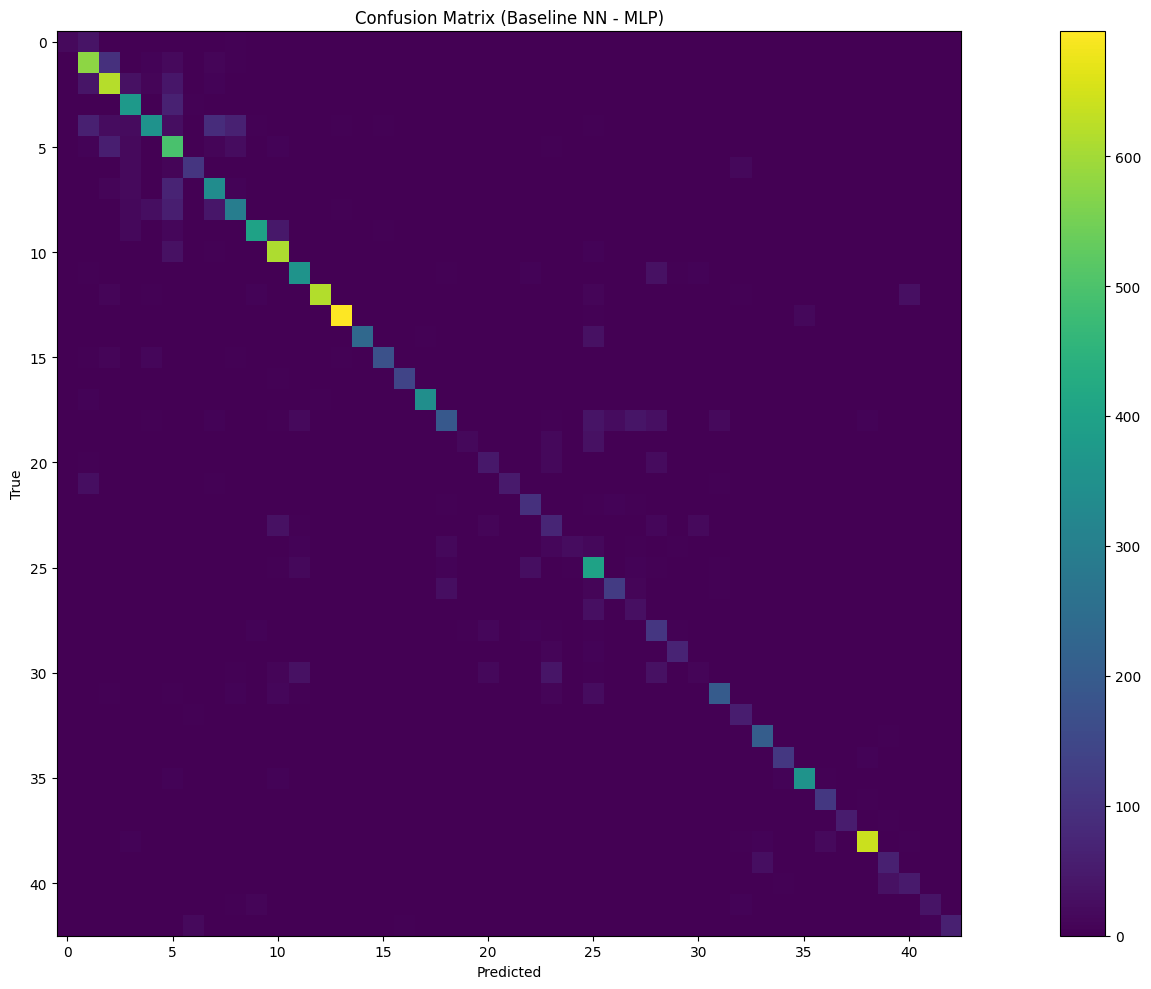

In [ ]:
## ✅ 5.1 Baseline Model: Simple Neural Network (MLP)

# Use non-augmented (base) transform for the baseline to keep it simple and comparable
baseline_train_ds = Subset(train_full_base, list(train_idx))
baseline_val_ds   = Subset(train_full_base, list(val_idx))

BASELINE_BATCH_SIZE = 128
baseline_train_loader = DataLoader(baseline_train_ds, batch_size=BASELINE_BATCH_SIZE, shuffle=True,  pin_memory=True, num_workers=0)
baseline_test_loader  = DataLoader(test_ds,          batch_size=BASELINE_BATCH_SIZE, shuffle=False, pin_memory=True, num_workers=0)

class BaselineMLP(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, img_size=IMG_SIZE, hidden1=512, hidden2=256, dropout_p=0.2):
        super().__init__()
        in_dim = 3 * img_size * img_size
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden1),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_p),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_p),
            nn.Linear(hidden2, num_classes)
        )

    def forward(self, x):
        return self.net(x)

mlp = BaselineMLP(num_classes=NUM_CLASSES, img_size=IMG_SIZE).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3)

BASELINE_EPOCHS = 10

def train_one_epoch_mlp(model, loader):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for x, y in tqdm(loader, desc="MLP Train", leave=False):
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        pred = logits.argmax(dim=1)
        correct += (pred == y).sum().item()
        total += x.size(0)

    return total_loss / max(total, 1), correct / max(total, 1)

@torch.no_grad()
def eval_mlp(model, loader):
    model.eval()
    all_y = []
    all_p = []
    for x, y in tqdm(loader, desc="MLP Eval", leave=False):
        x = x.to(device, non_blocking=True)
        logits = model(x)
        pred = logits.argmax(dim=1).cpu().numpy()
        all_p.append(pred)
        all_y.append(y.numpy())
    y_true = np.concatenate(all_y)
    y_pred = np.concatenate(all_p)
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average="macro")
    return y_true, y_pred, acc, f1

print("Training Baseline MLP...")
for epoch in range(1, BASELINE_EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch_mlp(mlp, baseline_train_loader)
    print(f"Epoch {epoch:02d}/{BASELINE_EPOCHS} | loss={tr_loss:.4f} | train_acc={tr_acc:.4f}")

# Final baseline evaluation on test set
y_test, mlp_pred_test, mlp_acc, mlp_f1 = eval_mlp(mlp, baseline_test_loader)

print("✅ Baseline MLP Test Accuracy:", mlp_acc)
print("✅ Baseline MLP Macro F1:", mlp_f1)

cm_mlp = confusion_matrix(y_test, mlp_pred_test, labels=np.arange(NUM_CLASSES))

fig, axs = plt.subplots(1, 1)
fig.set_size_inches(20, 10)

im = axs.imshow(cm_mlp, interpolation="nearest")
axs.set_title("Confusion Matrix (Baseline NN - MLP)")
axs.set_xlabel("Predicted")
axs.set_ylabel("True")

fig.colorbar(im, ax=axs)
plt.tight_layout()
plt.show()

In [ ]:
## ✅ 5.2 CNN Model Architecture (LeNet-5 Inspired)
class LeNet5InspiredCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, dropout_p=0.3, use_batchnorm=False):
        super().__init__()

        # conv block = Conv -> (BN optional) -> ReLU -> MaxPool
        def conv_block(in_ch, out_ch, k=5):
            layers = [nn.Conv2d(in_ch, out_ch, kernel_size=k, padding=k//2)]
            if use_batchnorm:
                layers.append(nn.BatchNorm2d(out_ch))  # Technique #3
            layers += [nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            return nn.Sequential(*layers)

        self.block1 = conv_block(3, 32, k=5)   # 32x32 -> 16x16
        self.block2 = conv_block(32, 64, k=5)  # 16x16 -> 8x8

        # Dropout (Technique #2)
        self.dropout = nn.Dropout(dropout_p)

        self.fc1 = nn.Linear(64 * (IMG_SIZE//4) * (IMG_SIZE//4), 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)  # logits
        return x

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model = LeNet5InspiredCNN(dropout_p=0.3, use_batchnorm=False).to(device)
print("LeNet5InspiredCNN params:", count_params(model))

LeNet5InspiredCNN params: 1113579


In [ ]:
## ✅ Training Utilities (loss/acc curves + best checkpoint by val accuracy)

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, n = 0.0, 0, 0

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        bs = x.size(0)
        total_loss += loss.item() * bs
        correct += (logits.argmax(1) == y).sum().item()
        n += bs

    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(x)
        loss = criterion(logits, y)

        bs = x.size(0)
        total_loss += loss.item() * bs
        correct += (logits.argmax(1) == y).sum().item()
        n += bs

    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=10, lr=1e-3, weight_decay=1e-4, title="CNN"):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = -1.0
    best_state = None

    for epoch in range(1, epochs+1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = evaluate(model, val_loader, criterion)
        dt = time.time() - t0

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)

        print(f"[{title}] Epoch {epoch:02d}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | time {dt:.1f}s")

        if va_acc > best_val_acc:
            best_val_acc = va_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    # Plot curves
    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1)
    plt.plot(history["train_loss"], label="train")
    plt.plot(history["val_loss"], label="val")
    plt.title(f"{title} Loss")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history["train_acc"], label="train")
    plt.plot(history["val_acc"], label="val")
    plt.title(f"{title} Accuracy")
    plt.xlabel("epoch"); plt.ylabel("acc"); plt.legend()

    plt.tight_layout()
    plt.show()

    return history, best_val_acc

@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    all_y, all_pred = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        logits = model(x)
        pred = logits.argmax(1).cpu().numpy()
        all_pred.append(pred)
        all_y.append(y.numpy())
    return np.concatenate(all_y), np.concatenate(all_pred)

### Reference CNN Run

Dropout 0.3, no batch normalization. Although originally labeled non-augmented, this run uses `train_ds`, which applies the augmentation transform.


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[LeNet5InspiredCNN (ref)] Epoch 01/10 | train loss 2.1620 acc 0.3730 | val loss 0.9319 acc 0.7297 | time 86.6s
[LeNet5InspiredCNN (ref)] Epoch 02/10 | train loss 1.0752 acc 0.6478 | val loss 0.4916 acc 0.8396 | time 82.5s
[LeNet5InspiredCNN (ref)] Epoch 03/10 | train loss 0.7843 acc 0.7407 | val loss 0.2756 acc 0.9229 | time 81.0s
[LeNet5InspiredCNN (ref)] Epoch 04/10 | train loss 0.6351 acc 0.7945 | val loss 0.2011 acc 0.9434 | time 82.8s
[LeNet5InspiredCNN (ref)] Epoch 05/10 | train loss 0.5428 acc 0.8273 | val loss 0.1408 acc 0.9700 | time 87.3s
[LeNet5InspiredCNN (ref)] Epoch 06/10 | train loss 0.4403 acc 0.8563 | val loss 0.1096 acc 0.9747 | time 88.5s
[LeNet5InspiredCNN (ref)] Epoch 07/10 | train loss 0.4005 acc 0.8694 | val loss 0.1135 acc 0.9665 | time 88.3s
[LeNet5InspiredCNN (ref)] Epoch 08/10 | train loss 0.3742 acc 0.8801 | val loss 0.0856 acc 0.9710 | time 88.6s
[LeNet5InspiredCNN (ref)] Epoch 09/10 | train loss 0.3406 acc 0.8906 | val loss 0.0537 acc 0.9875 | time 88.5s
[

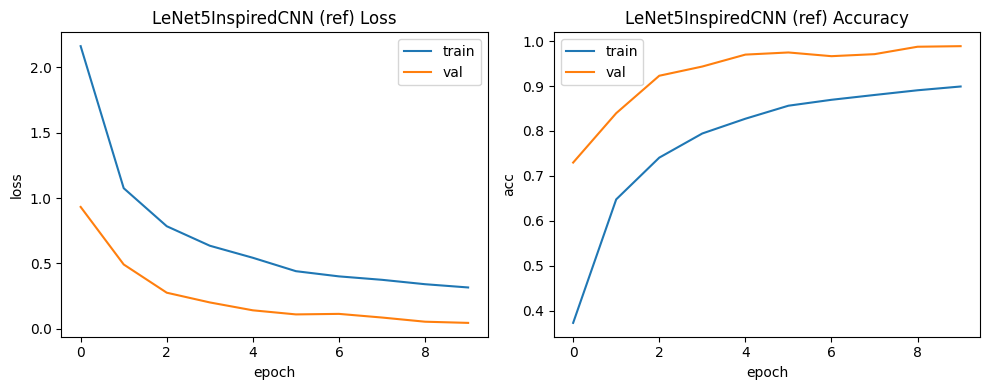


✅ CNN (ref) Test Accuracy: 0.913618368962787
✅ CNN (ref) Macro F1: 0.8763997240693944


In [ ]:
BATCH_SIZE = 64

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True, num_workers=0)

train_loader_aug = DataLoader(train_full_aug, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=0)

EPOCHS = 10
cnn_ref = LeNet5InspiredCNN(dropout_p=0.3, use_batchnorm=False).to(device)

history_ref, best_val_ref = fit(
    cnn_ref,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    lr=1e-3,
    weight_decay=1e-4,
    title="LeNet5InspiredCNN (ref)"
)

# Test performance
criterion = nn.CrossEntropyLoss()
test_loss_ref, test_acc_ref = evaluate(cnn_ref, test_loader, criterion)
print("\n✅ CNN (ref) Test Accuracy:", test_acc_ref)

y_true_cnn, y_pred_cnn = predict_all(cnn_ref, test_loader)
cnn_f1 = f1_score(y_true_cnn, y_pred_cnn, average="macro")
print("✅ CNN (ref) Macro F1:", cnn_f1)

### 6) Training Configuration Experiments

Compare dropout rates, batch normalization, and two training loader configurations. All CNN training loaders in this notebook apply augmentation; the loader for EXP1 additionally includes the validation images. These saved runs are not a controlled augmentation-only comparison.



Running: ExperimentConfig(name='EXP0_ref_noaug_dp0.3_noBN', use_aug=False, dropout_p=0.3, use_bn=False, epochs=10, lr=0.001, weight_decay=0.0001)


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[EXP0_ref_noaug_dp0.3_noBN] Epoch 01/10 | train loss 2.1081 acc 0.3906 | val loss 0.8316 acc 0.7457 | time 79.3s
[EXP0_ref_noaug_dp0.3_noBN] Epoch 02/10 | train loss 0.9745 acc 0.6856 | val loss 0.3720 acc 0.8914 | time 80.2s
[EXP0_ref_noaug_dp0.3_noBN] Epoch 03/10 | train loss 0.6777 acc 0.7820 | val loss 0.2020 acc 0.9409 | time 79.8s
[EXP0_ref_noaug_dp0.3_noBN] Epoch 04/10 | train loss 0.5378 acc 0.8270 | val loss 0.1447 acc 0.9627 | time 80.3s
[EXP0_ref_noaug_dp0.3_noBN] Epoch 05/10 | train loss 0.4467 acc 0.8522 | val loss 0.1033 acc 0.9715 | time 85.6s
[EXP0_ref_noaug_dp0.3_noBN] Epoch 06/10 | train loss 0.3866 acc 0.8758 | val loss 0.0845 acc 0.9787 | time 87.0s
[EXP0_ref_noaug_dp0.3_noBN] Epoch 07/10 | train loss 0.3458 acc 0.8887 | val loss 0.0559 acc 0.9840 | time 86.5s
[EXP0_ref_noaug_dp0.3_noBN] Epoch 08/10 | train loss 0.3252 acc 0.8956 | val loss 0.0478 acc 0.9897 | time 86.7s
[EXP0_ref_noaug_dp0.3_noBN] Epoch 09/10 | train loss 0.2841 acc 0.9096 | val loss 0.0411 acc 0.9

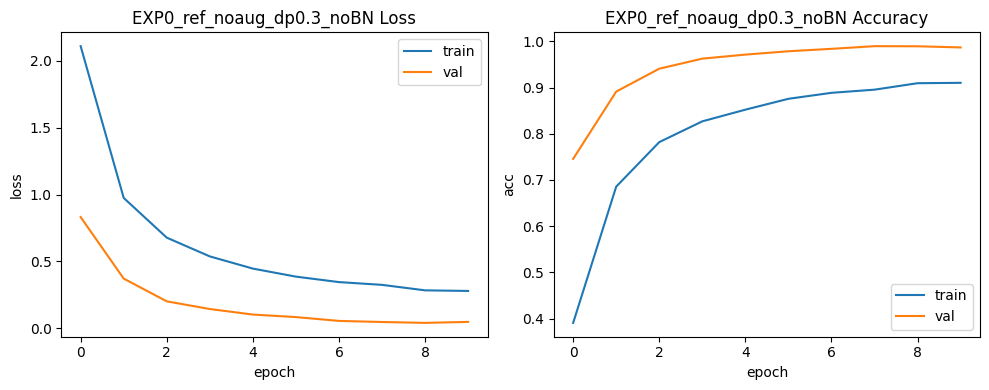


Running: ExperimentConfig(name='EXP1_AUG_dp0.3_noBN', use_aug=True, dropout_p=0.3, use_bn=False, epochs=10, lr=0.001, weight_decay=0.0001)


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[EXP1_AUG_dp0.3_noBN] Epoch 01/10 | train loss 1.9393 acc 0.4274 | val loss 0.6772 acc 0.7863 | time 92.8s
[EXP1_AUG_dp0.3_noBN] Epoch 02/10 | train loss 0.8952 acc 0.7079 | val loss 0.3344 acc 0.9107 | time 92.3s
[EXP1_AUG_dp0.3_noBN] Epoch 03/10 | train loss 0.6431 acc 0.7906 | val loss 0.2010 acc 0.9499 | time 91.6s
[EXP1_AUG_dp0.3_noBN] Epoch 04/10 | train loss 0.5204 acc 0.8315 | val loss 0.1227 acc 0.9655 | time 96.3s
[EXP1_AUG_dp0.3_noBN] Epoch 05/10 | train loss 0.4356 acc 0.8580 | val loss 0.0936 acc 0.9747 | time 98.5s
[EXP1_AUG_dp0.3_noBN] Epoch 06/10 | train loss 0.3838 acc 0.8782 | val loss 0.0780 acc 0.9805 | time 98.5s
[EXP1_AUG_dp0.3_noBN] Epoch 07/10 | train loss 0.3414 acc 0.8898 | val loss 0.0536 acc 0.9857 | time 100.4s
[EXP1_AUG_dp0.3_noBN] Epoch 08/10 | train loss 0.3192 acc 0.8990 | val loss 0.0669 acc 0.9842 | time 101.0s
[EXP1_AUG_dp0.3_noBN] Epoch 09/10 | train loss 0.2860 acc 0.9089 | val loss 0.0294 acc 0.9940 | time 100.2s
[EXP1_AUG_dp0.3_noBN] Epoch 10/10 

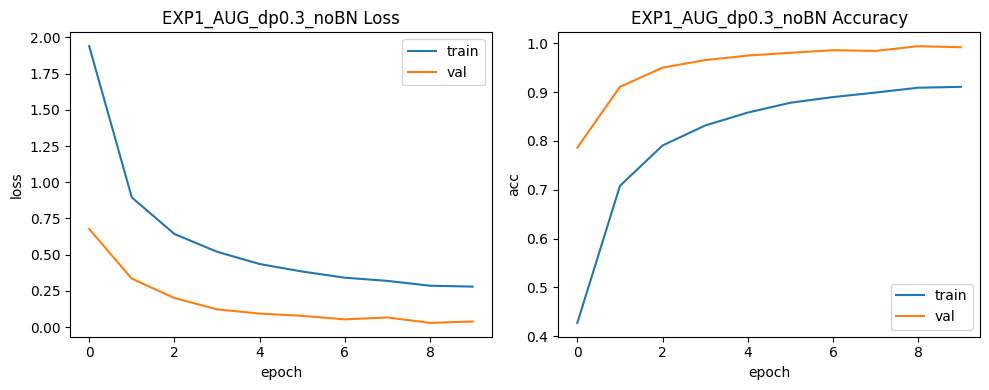


Running: ExperimentConfig(name='EXP2_noaug_dp0.2_noBN', use_aug=False, dropout_p=0.2, use_bn=False, epochs=10, lr=0.001, weight_decay=0.0001)


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[EXP2_noaug_dp0.2_noBN] Epoch 01/10 | train loss 1.8887 acc 0.4499 | val loss 0.6544 acc 0.7898 | time 79.3s
[EXP2_noaug_dp0.2_noBN] Epoch 02/10 | train loss 0.7550 acc 0.7576 | val loss 0.2047 acc 0.9399 | time 79.0s
[EXP2_noaug_dp0.2_noBN] Epoch 03/10 | train loss 0.5122 acc 0.8371 | val loss 0.1431 acc 0.9577 | time 78.8s
[EXP2_noaug_dp0.2_noBN] Epoch 04/10 | train loss 0.3808 acc 0.8785 | val loss 0.1609 acc 0.9552 | time 80.3s
[EXP2_noaug_dp0.2_noBN] Epoch 05/10 | train loss 0.2981 acc 0.9057 | val loss 0.0632 acc 0.9805 | time 83.9s
[EXP2_noaug_dp0.2_noBN] Epoch 06/10 | train loss 0.2607 acc 0.9163 | val loss 0.0464 acc 0.9877 | time 87.2s
[EXP2_noaug_dp0.2_noBN] Epoch 07/10 | train loss 0.2372 acc 0.9252 | val loss 0.0475 acc 0.9862 | time 87.3s
[EXP2_noaug_dp0.2_noBN] Epoch 08/10 | train loss 0.2160 acc 0.9318 | val loss 0.0415 acc 0.9887 | time 87.3s
[EXP2_noaug_dp0.2_noBN] Epoch 09/10 | train loss 0.1889 acc 0.9395 | val loss 0.0313 acc 0.9947 | time 87.6s
[EXP2_noaug_dp0.2_n

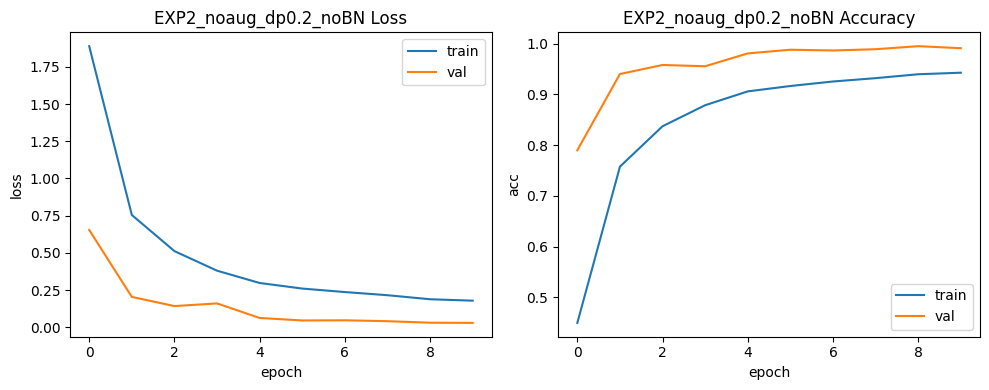


Running: ExperimentConfig(name='EXP3_noaug_dp0.5_noBN', use_aug=False, dropout_p=0.5, use_bn=False, epochs=10, lr=0.001, weight_decay=0.0001)


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[EXP3_noaug_dp0.5_noBN] Epoch 01/10 | train loss 2.3672 acc 0.3242 | val loss 1.1896 acc 0.6036 | time 80.1s
[EXP3_noaug_dp0.5_noBN] Epoch 02/10 | train loss 1.3529 acc 0.5636 | val loss 0.6459 acc 0.8131 | time 78.9s
[EXP3_noaug_dp0.5_noBN] Epoch 03/10 | train loss 1.0440 acc 0.6542 | val loss 0.3666 acc 0.8954 | time 79.2s
[EXP3_noaug_dp0.5_noBN] Epoch 04/10 | train loss 0.8750 acc 0.7140 | val loss 0.3117 acc 0.9012 | time 79.3s
[EXP3_noaug_dp0.5_noBN] Epoch 05/10 | train loss 0.7354 acc 0.7608 | val loss 0.2045 acc 0.9585 | time 82.0s
[EXP3_noaug_dp0.5_noBN] Epoch 06/10 | train loss 0.6476 acc 0.7874 | val loss 0.1496 acc 0.9667 | time 82.1s
[EXP3_noaug_dp0.5_noBN] Epoch 07/10 | train loss 0.5971 acc 0.8072 | val loss 0.1123 acc 0.9690 | time 82.9s
[EXP3_noaug_dp0.5_noBN] Epoch 08/10 | train loss 0.5395 acc 0.8270 | val loss 0.0935 acc 0.9825 | time 82.2s
[EXP3_noaug_dp0.5_noBN] Epoch 09/10 | train loss 0.4979 acc 0.8381 | val loss 0.0926 acc 0.9747 | time 83.4s
[EXP3_noaug_dp0.5_n

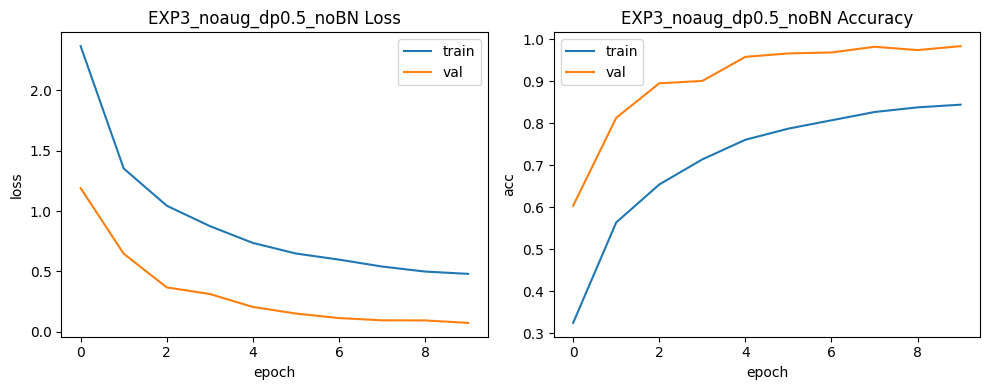


Running: ExperimentConfig(name='EXP4_noaug_dp0.3_BN', use_aug=False, dropout_p=0.3, use_bn=True, epochs=10, lr=0.001, weight_decay=0.0001)


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[EXP4_noaug_dp0.3_BN] Epoch 01/10 | train loss 2.2751 acc 0.3363 | val loss 1.1531 acc 0.6314 | time 87.8s
[EXP4_noaug_dp0.3_BN] Epoch 02/10 | train loss 1.1966 acc 0.6060 | val loss 0.5641 acc 0.8211 | time 87.1s
[EXP4_noaug_dp0.3_BN] Epoch 03/10 | train loss 0.8821 acc 0.7051 | val loss 0.3612 acc 0.8879 | time 88.4s
[EXP4_noaug_dp0.3_BN] Epoch 04/10 | train loss 0.7154 acc 0.7627 | val loss 0.2577 acc 0.9327 | time 89.3s
[EXP4_noaug_dp0.3_BN] Epoch 05/10 | train loss 0.6070 acc 0.8021 | val loss 0.1831 acc 0.9469 | time 95.0s
[EXP4_noaug_dp0.3_BN] Epoch 06/10 | train loss 0.5309 acc 0.8263 | val loss 0.1399 acc 0.9647 | time 100.3s
[EXP4_noaug_dp0.3_BN] Epoch 07/10 | train loss 0.4589 acc 0.8489 | val loss 0.0983 acc 0.9780 | time 102.9s
[EXP4_noaug_dp0.3_BN] Epoch 08/10 | train loss 0.4181 acc 0.8642 | val loss 0.0882 acc 0.9755 | time 104.5s
[EXP4_noaug_dp0.3_BN] Epoch 09/10 | train loss 0.3904 acc 0.8718 | val loss 0.1043 acc 0.9682 | time 107.1s
[EXP4_noaug_dp0.3_BN] Epoch 10/10

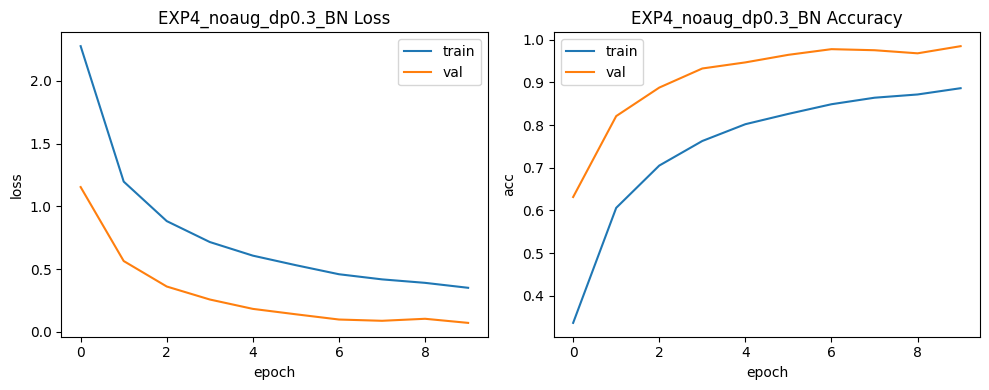

,Experiment,Augmentation,Dropout,BatchNorm,Best Val Acc,Test Acc,Macro F1
1,EXP1_AUG_dp0.3_noBN,True,0.3,False,0.993994,0.929216,0.906072
4,EXP4_noaug_dp0.3_BN,False,0.3,True,0.984985,0.925099,0.886939
2,EXP2_noaug_dp0.2_noBN,False,0.2,False,0.994745,0.923911,0.884843
0,EXP0_ref_noaug_dp0.3_noBN,False,0.3,False,0.989740,0.922249,0.887806
3,EXP3_noaug_dp0.5_noBN,False,0.5,False,0.983984,0.911718,0.883683


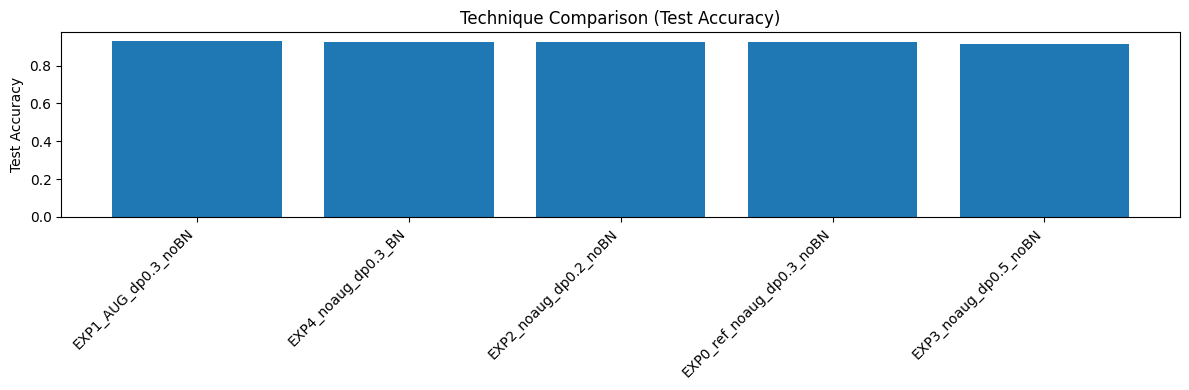


✅ Best experiment: EXP1_AUG_dp0.3_noBN | Test Acc: 0.9292161520190024 | Macro F1: 0.9060721652060117


In [ ]:
@dataclass
class ExperimentConfig:
    name: str
    use_aug: bool
    dropout_p: float
    use_bn: bool
    epochs: int = 10
    lr: float = 1e-3
    weight_decay: float = 1e-4

def run_experiment(cfg: ExperimentConfig):
    train_ld = train_loader_aug if cfg.use_aug else train_loader
    model = LeNet5InspiredCNN(dropout_p=cfg.dropout_p, use_batchnorm=cfg.use_bn).to(device)

    hist, best_val = fit(
        model, train_ld, val_loader,
        epochs=cfg.epochs, lr=cfg.lr, weight_decay=cfg.weight_decay,
        title=cfg.name
    )
    criterion = nn.CrossEntropyLoss()
    _, test_acc = evaluate(model, test_loader, criterion)

    y_t, y_p = predict_all(model, test_loader)
    macro_f1 = f1_score(y_t, y_p, average="macro")

    return {
        "Experiment": cfg.name,
        "Augmentation": cfg.use_aug,
        "Dropout": cfg.dropout_p,
        "BatchNorm": cfg.use_bn,
        "Best Val Acc": best_val,
        "Test Acc": test_acc,
        "Macro F1": macro_f1,
        "state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
        "y_true": y_t,
        "y_pred": y_p,
    }

experiments = [
    ExperimentConfig("EXP0_ref_noaug_dp0.3_noBN", use_aug=False, dropout_p=0.3, use_bn=False),
    ExperimentConfig("EXP1_AUG_dp0.3_noBN",      use_aug=True,  dropout_p=0.3, use_bn=False),
    ExperimentConfig("EXP2_noaug_dp0.2_noBN",    use_aug=False, dropout_p=0.2, use_bn=False),
    ExperimentConfig("EXP3_noaug_dp0.5_noBN",    use_aug=False, dropout_p=0.5, use_bn=False),
    ExperimentConfig("EXP4_noaug_dp0.3_BN",      use_aug=False, dropout_p=0.3, use_bn=True),
]

results = []
best = None
best_test = -1.0

for cfg in experiments:
    print("\n" + "="*90)
    print("Running:", cfg)
    out = run_experiment(cfg)
    results.append(out)
    if out["Test Acc"] > best_test:
        best_test = out["Test Acc"]
        best = out

summary_df = pd.DataFrame(results).drop(columns=["state_dict","y_true","y_pred"])
summary_df = summary_df.sort_values("Test Acc", ascending=False)
display(summary_df)

plt.figure(figsize=(12,4))
plt.bar(summary_df["Experiment"], summary_df["Test Acc"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Test Accuracy")
plt.title("Technique Comparison (Test Accuracy)")
plt.tight_layout()
plt.show()

print("\n✅ Best experiment:", best["Experiment"], "| Test Acc:", best["Test Acc"], "| Macro F1:", best["Macro F1"])

### 7) Performance Evaluation (Tables + Plots)

We report:
- Accuracy
- Confusion matrix
- Macro F1-score
- Learning curves

### 8) Comparison of Approaches

We compare:
- Baseline NN vs best CNN
- CNN reference vs CNN improved techniques

,Model,Test Acc,Macro F1
0,Baseline NN (MLP),0.786857,0.724467
1,Best CNN (LeNet5-inspired),0.929216,0.906072


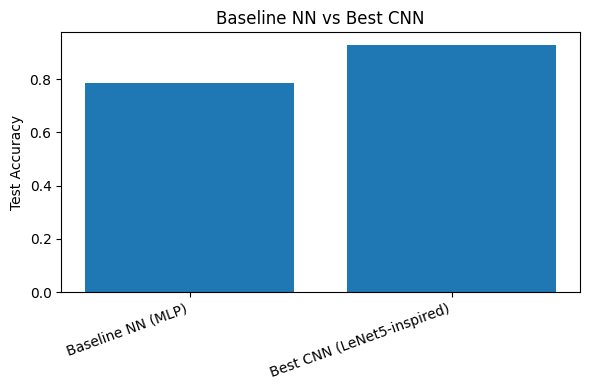

In [ ]:
best_cnn_acc = best["Test Acc"]
best_cnn_f1  = best["Macro F1"]

comparison_df = pd.DataFrame([
    {"Model": "Baseline NN (MLP)", "Test Acc": mlp_acc, "Macro F1": mlp_f1},
    {"Model": "Best CNN (LeNet5-inspired)", "Test Acc": best_cnn_acc, "Macro F1": best_cnn_f1},
])

display(comparison_df)

plt.figure(figsize=(6,4))
plt.bar(comparison_df["Model"], comparison_df["Test Acc"])
plt.xticks(rotation=20, ha="right")
plt.ylabel("Test Accuracy")
plt.title("Baseline NN vs Best CNN")
plt.tight_layout()
plt.show()

### 9) Foundation Model Comparison (CLIP)

We implement a foundation model approach using **CLIP zero-shot classification** and compare it to our CNN.

CLIP backend: transformers | Available: True


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

... (6 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP zero-shot (transformers):   0%|          | 0/99 [00:00<?, ?it/s]


✅ CLIP Zero-shot Accuracy: 0.30451306413301665


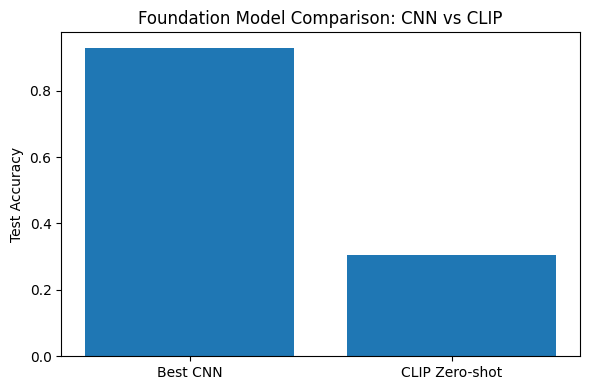

In [ ]:
CLIP_AVAILABLE = True
clip_backend = None

try:
    import open_clip
    clip_backend = "open_clip"
except Exception:
    clip_backend = None

if clip_backend is None:
    try:
        from transformers import CLIPProcessor, CLIPModel
        clip_backend = "transformers"
    except Exception:
        CLIP_AVAILABLE = False

print("CLIP backend:", clip_backend, "| Available:", CLIP_AVAILABLE)

NUM_WORKERS = 0

@torch.no_grad()
def evaluate_clip_zero_shot(batch_size=128):
    if not CLIP_AVAILABLE:
        return None

    if clip_backend == "open_clip":
        import open_clip
        model_name = "ViT-B-32"
        pretrained = "openai"
        clip_model, _, preprocess = open_clip.create_model_and_transforms(model_name, pretrained=pretrained)
        tokenizer = open_clip.get_tokenizer(model_name)
        clip_model = clip_model.to(device).eval()

        prompts = [f"a photo of a traffic sign: {name}" for name in GTSRB_LABELS]
        text_tokens = tokenizer(prompts).to(device)
        text_features = clip_model.encode_text(text_tokens)
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)

        clip_test = GTSRB(root=DATA_DIR, split="test", download=False, transform=preprocess)
        clip_loader = DataLoader(clip_test, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)

        y_true, y_pred = [], []
        for images, labels in tqdm(clip_loader, desc="CLIP zero-shot (open_clip)"):
            images = images.to(device)
            image_features = clip_model.encode_image(images)
            image_features = image_features / image_features.norm(dim=-1, keepdim=True)
            logits = image_features @ text_features.T
            preds = torch.argmax(logits, dim=1).cpu().numpy()
            y_pred.append(preds)
            y_true.append(labels.numpy())

        y_true = np.concatenate(y_true)
        y_pred = np.concatenate(y_pred)

    else:
        from transformers import CLIPProcessor, CLIPModel
        model_id = "openai/clip-vit-base-patch32"
        clip_model = CLIPModel.from_pretrained(model_id).to(device).eval()
        processor = CLIPProcessor.from_pretrained(model_id)

        prompts = [f"a photo of a traffic sign: {name}" for name in GTSRB_LABELS]
        text_inputs = processor(text=prompts, return_tensors="pt", padding=True).to(device)

        # Use get_text_features which returns features in the common embedding space (512 for this model)
        text_features_output = clip_model.get_text_features(**text_inputs)
        text_features = text_features_output.pooler_output if hasattr(text_features_output, 'pooler_output') else text_features_output
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)

        clip_test_pil = GTSRB(root=DATA_DIR, split="test", download=False, transform=None)

        # Custom collate_fn to process PIL Images with the CLIP processor
        def custom_clip_collate_fn(batch):
            images = [item[0] for item in batch]
            labels = torch.tensor([item[1] for item in batch])
            # Process images with the CLIP processor, which handles resizing, normalization, and tensor conversion
            processed_inputs = processor(images=images, return_tensors="pt", padding=True)
            return processed_inputs['pixel_values'], labels

        clip_loader = DataLoader(clip_test_pil, batch_size=batch_size, shuffle=False, num_workers=0, collate_fn=custom_clip_collate_fn)

        y_true, y_pred = [], []
        for images, labels in tqdm(clip_loader, desc="CLIP zero-shot (transformers)"):
            images = images.to(device) # pixel_values are already tensors from collate_fn

            # Create a dictionary for pixel_values as expected by get_image_features
            image_inputs = {'pixel_values': images}
            # Use get_image_features which returns features in the common embedding space (512 for this model)
            image_features_output = clip_model.get_image_features(**image_inputs)
            image_features = image_features_output.pooler_output if hasattr(image_features_output, 'pooler_output') else image_features_output
            image_features = image_features / image_features.norm(dim=-1, keepdim=True)

            logits = image_features @ text_features.T
            preds = torch.argmax(logits, dim=1).cpu().numpy()
            y_pred.append(preds)
            y_true.append(labels.numpy())

        y_true = np.concatenate(y_true)
        y_pred = np.concatenate(y_pred)

    acc = (y_true == y_pred).mean()
    return acc, y_true, y_pred

clip_out = evaluate_clip_zero_shot(batch_size=128)
if clip_out is None:
    print("Skipping CLIP section: install open_clip_torch or transformers.")
else:
    clip_acc, clip_true, clip_pred = clip_out
    print("\n✅ CLIP Zero-shot Accuracy:", clip_acc)

    plt.figure(figsize=(6,4))
    plt.bar(["Best CNN", "CLIP Zero-shot"], [best_cnn_acc, clip_acc])
    plt.ylabel("Test Accuracy")
    plt.title("Foundation Model Comparison: CNN vs CLIP")
    plt.tight_layout()
    plt.show()

### 10) Error and Failure Analysis

We analyze:
- Confusion matrix for best CNN
- Top confusion pairs (true → predicted)
- Visual examples of misclassified images

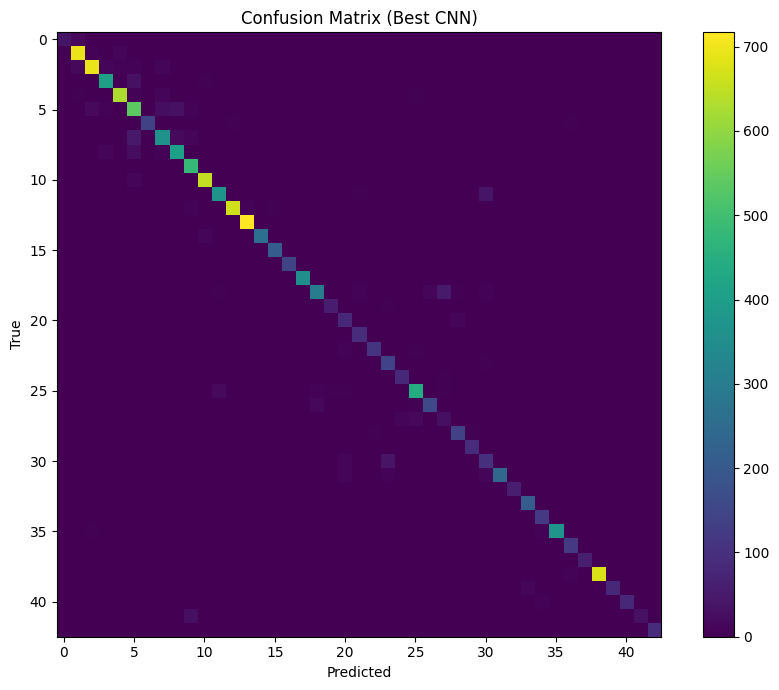

Top confusion pairs (true -> pred):
  18 (General caution) -> 27 (Pedestrians) : 52
  07 (Speed limit (100km/h)) -> 05 (Speed limit (80km/h)) : 50
  11 (Right-of-way at the next intersection) -> 30 (Beware of ice/snow) : 40
  30 (Beware of ice/snow) -> 23 (Slippery road) : 38
  03 (Speed limit (60km/h)) -> 05 (Speed limit (80km/h)) : 32
  05 (Speed limit (80km/h)) -> 08 (Speed limit (120km/h)) : 31
  05 (Speed limit (80km/h)) -> 07 (Speed limit (100km/h)) : 28
  41 (End of no passing) -> 09 (No passing) : 28
  08 (Speed limit (120km/h)) -> 05 (Speed limit (80km/h)) : 25
  25 (Road work) -> 11 (Right-of-way at the next intersection) : 19

Total misclassified: 894 out of 12630


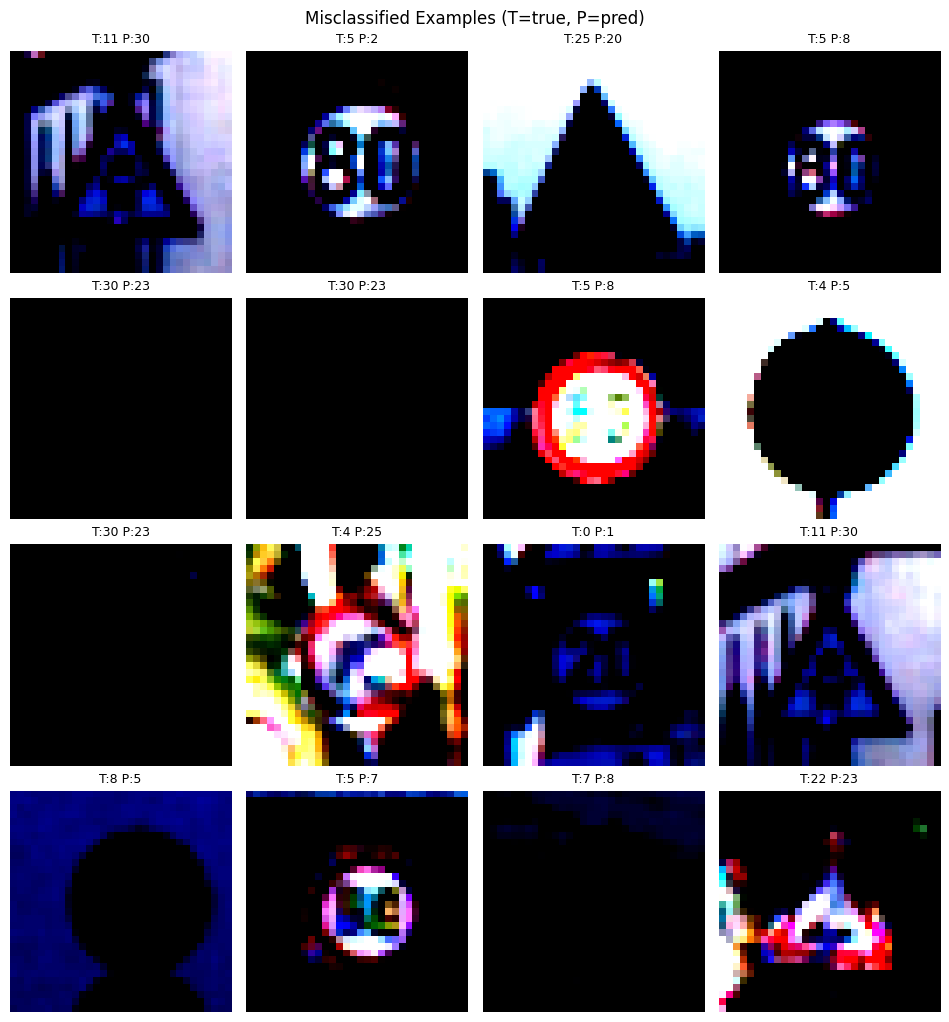

In [ ]:
best_y_true = best["y_true"]
best_y_pred = best["y_pred"]

cm_best = confusion_matrix(best_y_true, best_y_pred, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(9,7))
plt.imshow(cm_best, interpolation="nearest")
plt.title("Confusion Matrix (Best CNN)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.colorbar()
plt.tight_layout()
plt.show()

cm_off = cm_best.copy()
np.fill_diagonal(cm_off, 0)

K = 10
flat_idx = np.argsort(cm_off.ravel())[::-1][:K]
pairs = [(idx // NUM_CLASSES, idx % NUM_CLASSES, cm_off.ravel()[idx]) for idx in flat_idx if cm_off.ravel()[idx] > 0]

print("Top confusion pairs (true -> pred):")
for t, p, c in pairs:
    print(f"  {t:02d} ({GTSRB_LABELS[t]}) -> {p:02d} ({GTSRB_LABELS[p]}) : {c}")

mis_idx = np.where(best_y_true != best_y_pred)[0]
print("\nTotal misclassified:", len(mis_idx), "out of", len(best_y_true))

def show_misclassified(dataset, y_true, y_pred, n=16):
    pick = np.random.choice(mis_idx, size=min(n, len(mis_idx)), replace=False)
    cols = int(math.sqrt(len(pick)))
    rows = int(math.ceil(len(pick)/cols))

    plt.figure(figsize=(cols*2.4, rows*2.6))
    for i, idx in enumerate(pick):
        img, _ = dataset[idx]
        plt.subplot(rows, cols, i+1)
        plt.imshow(np.transpose(img.numpy(), (1,2,0)))
        t = int(y_true[idx]); p = int(y_pred[idx])
        plt.title(f"T:{t} P:{p}", fontsize=9)
        plt.axis("off")
    plt.suptitle("Misclassified Examples (T=true, P=pred)")
    plt.tight_layout()
    plt.show()

show_misclassified(test_ds, best_y_true, best_y_pred, n=16)

#### 10.1 Subset Confusion Matrices (Visually Similar Classes)

To highlight fine-grained differences (where CNNs usually outperform simple fully connected neural networks), we evaluate subset confusion matrices.

Example subset: Speed limit signs that share the same general shape and color but differ only in the digit/number.

We keep the ground truth unchanged (original GTSRB labels).
This subset analysis is used for focused evaluation and interpretability.


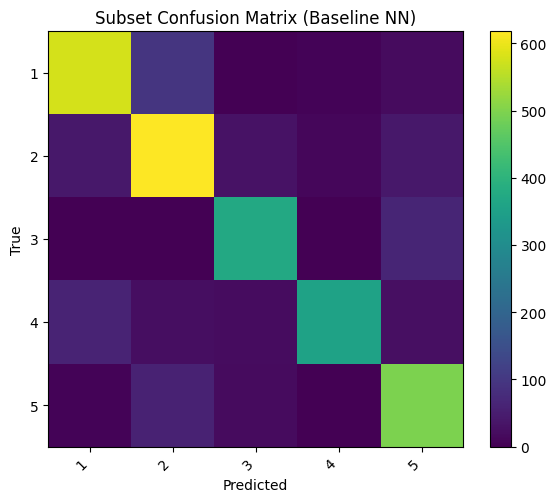

Subset size: 3210 | Subset Acc: 0.7539 | Subset Macro F1: 0.1706


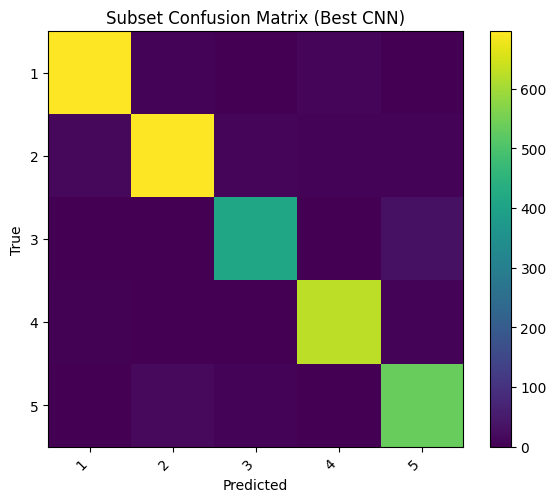

Subset size: 3210 | Subset Acc: 0.9237 | Subset Macro F1: 0.2606

Subset class names:
  01: Speed limit (30km/h)
  02: Speed limit (50km/h)
  03: Speed limit (60km/h)
  04: Speed limit (70km/h)
  05: Speed limit (80km/h)


In [ ]:
# ✅ Subset Confusion Matrix Utility
# Choose a subset that shares shape/color but differs in fine-grained features.
target_classes = [1, 2, 3, 4, 5]  # speed limits: 30,50,60,70,80 (class IDs may vary)

def plot_subset_confusion_matrix(y_true, y_pred, classes, title):
    classes = list(classes)
    mask = np.isin(y_true, classes)
    y_true_sub = y_true[mask]
    y_pred_sub = y_pred[mask]

    cm = confusion_matrix(y_true_sub, y_pred_sub, labels=classes)

    plt.figure(figsize=(6,5))
    plt.imshow(cm, interpolation="nearest")
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.xticks(range(len(classes)), classes, rotation=45, ha="right")
    plt.yticks(range(len(classes)), classes)
    plt.colorbar()
    plt.tight_layout()
    plt.show()

    # Quick numeric summary
    acc_sub = (y_true_sub == y_pred_sub).mean() if len(y_true_sub) else float("nan")
    f1_sub  = f1_score(y_true_sub, y_pred_sub, average="macro") if len(y_true_sub) else float("nan")
    print(f"Subset size: {len(y_true_sub)} | Subset Acc: {acc_sub:.4f} | Subset Macro F1: {f1_sub:.4f}")
    return cm

# --- Baseline NN (MLP) subset CM ---
# NOTE: y_test and pred_test were produced in the SVM section.
_ = plot_subset_confusion_matrix(
    y_true=y_test,
    y_pred=mlp_pred_test,
    classes=target_classes,
    title="Subset Confusion Matrix (Baseline NN)"
)

# --- Best CNN subset CM ---
# NOTE: best_y_true and best_y_pred were produced in the Best CNN section.
_ = plot_subset_confusion_matrix(
    y_true=best_y_true,
    y_pred=best_y_pred,
    classes=target_classes,
    title="Subset Confusion Matrix (Best CNN)"
)

print("\nSubset class names:")
for cid in target_classes:
    print(f"  {cid:02d}: {GTSRB_LABELS[cid]}")

## Implementation Scope

The notebook includes an MLP, a LeNet-5-inspired CNN, dropout and batch-normalization variants, image augmentation, zero-shot CLIP evaluation, and confusion/error analysis.


## Conclusion

The saved MLP run achieved 78.69% accuracy and 0.7245 macro F1. The reference CNN achieved 91.36% accuracy and 0.8764 macro F1. EXP1 recorded 92.92% accuracy and 0.9061 macro F1, while zero-shot CLIP recorded 30.45% accuracy.

EXP1 was selected by test accuracy and trained with images overlapping the validation subset. All CNN loaders apply augmentation despite some experiment labels. These results are exploratory, and do not establish an unbiased augmentation benefit. Future evaluation should fix loader membership, select configurations using an independent validation set, and evaluate the selected model once on the test set.

The saved EXP1 predictions include 894 errors among 12,630 test images. Confusions include visually similar speed limits and warning signs.
